# Assignment 4: Machine Translation with LSTM, GRU and Encoder–Decoder Models

**Course:** CS4101 | CS6103 — English → Hindi translation on the IIT Bombay parallel corpus

| Member | Roll number |
|---|---|
| Anshul Kaushal | 2611AI10 |
| Aditya Sharma | 2611CS11 |
| Roland Zohmingthana | 2611MC03 |

**Notebook layout**

0. Setup, seeds and determinism
1. Dataset: download, cleaning, tokenisation, fixed-seed subset, statistics
2. Task 1: RNN/LSTM/GRU cells from scratch, verification, parameter counts, gradient flow,
   BLEU-4 implementation, encoder–decoder model, training loop
3. Task 2: LSTM/GRU × hidden size {64, 128}
4. Task 3: final model selection, single test evaluation, error analysis
5. Seed sensitivity of the model ranking

**Restrictions respected.** Only the Python standard library, `numpy`, `pandas`, `matplotlib`,
`seaborn`, `torch` and `sacrebleu` are imported. Built-in recurrent layers (`nn.LSTM`, `nn.GRU`,
`nn.RNN` and their `*Cell` variants) are used *only* inside the verification cell of Task 1. The
corpus is fetched over plain HTTPS with `urllib` (no Hugging Face libraries) and read with
`pandas.read_parquet` (which uses `pyarrow` as its parquet engine). No attention, Transformers or
pretrained models are used.

The notebook runs end to end with *Run All* and writes every figure (`figures/`), every number
quoted in the report (`results/`) and the model checkpoints (`checkpoints/`) next to itself.

## 0. Setup

In [1]:
import os

# cuBLAS needs a fixed workspace size for deterministic matrix multiplications.
# This must be set before CUDA is initialised, i.e. before torch is imported.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import copy
import json
import math
import random
import re
import shutil
import time
import unicodedata
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import sacrebleu

SEED = 42  # global seed for subset selection, initialisation and shuffling


def set_seed(seed):
    """Seed every random number generator that this notebook uses."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

# Deterministic kernels. Any op without a deterministic implementation raises an error,
# so a successful run guarantees bit-for-bit repeatability on the same hardware/software.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figures"
RES_DIR = BASE_DIR / "results"
CKPT_DIR = BASE_DIR / "checkpoints"
for d in (DATA_DIR, FIG_DIR, RES_DIR, CKPT_DIR):
    d.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 80)

print("torch", torch.__version__, "| sacrebleu", sacrebleu.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

torch 2.13.0+cu126 | sacrebleu 2.6.0 | numpy 2.5.4 | pandas 3.1.1
device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Dataset

### 1.1 Download
The IIT Bombay English–Hindi corpus is hosted on the Hugging Face Hub as parquet files. We download
only the official *train* split (1.66 M pairs) with `urllib`, resuming interrupted transfers and
checking the parquet magic bytes. The official dev/test splits are news sentences that are almost
all longer than 10 tokens, so our train/validation/test splits are all carved out of one fixed-seed
subset of the train split (Section 1.4).

In [2]:
HF_URL = ("https://huggingface.co/datasets/cfilt/iitb-english-hindi/resolve/main/"
          "data/train-00000-of-00001.parquet")
RAW_PATH = DATA_DIR / "iitb_train.parquet"


def is_complete_parquet(path):
    """A complete parquet file starts and ends with the magic bytes b'PAR1'."""
    if not path.exists() or path.stat().st_size < 8:
        return False
    with open(path, "rb") as f:
        head = f.read(4)
        f.seek(-4, os.SEEK_END)
        tail = f.read(4)
    return head == b"PAR1" and tail == b"PAR1"


def download(url, path, attempts=10):
    """Download `url` to `path` with HTTP range-resume (the file is ~190 MB)."""
    if is_complete_parquet(path):
        return path
    part = path.with_suffix(".part")
    for attempt in range(attempts):
        start = part.stat().st_size if part.exists() else 0
        headers = {"Range": f"bytes={start}-"} if start else {}
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=headers), timeout=60) as r:
                mode = "ab" if (start and r.status == 206) else "wb"  # restart if range ignored
                with open(part, mode) as f:
                    shutil.copyfileobj(r, f, 1 << 20)
        except Exception as e:  # network hiccup -> resume on next attempt
            print(f"attempt {attempt}: {e!r}; resuming")
        if is_complete_parquet(part):
            part.replace(path)
            return path
    raise RuntimeError("download failed")


download(HF_URL, RAW_PATH)
raw = pd.read_parquet(RAW_PATH)
raw_en = raw["translation"].map(lambda d: d["en"]).tolist()
raw_hi = raw["translation"].map(lambda d: d["hi"]).tolist()
del raw
print(f"raw pairs: {len(raw_en):,} | unique English sentences: {len(set(raw_en)):,}")

raw pairs: 1,659,083 | unique English sentences: 1,093,624


### 1.2 Tokenisation

**English.** Unicode NFKC, lower-casing, curly quotes → ASCII quotes, then a regular expression
that keeps words (with clitics such as `'s`), numbers and single punctuation marks as tokens.

**Hindi.** Hindi needs a Devanagari-aware tokeniser because vowel signs (*matras*, e.g. `ि`, `ा`),
the *virama* `्`, *anusvara* `ं` and *nukta* `़` are combining marks that Python's `\w` does not
treat as word characters; a `\w+` tokeniser would cut words such as `हिन्दी` into fragments. Our
choices:

1. **Unicode NFC** plus removal of zero-width joiners, so the same word always has the same code
   point sequence (e.g. pre-composed nukta letters such as `क़` become `क` + `़` consistently).
2. **Sentence-ending punctuation.** The corpus ends Hindi sentences inconsistently with the
   *danda* `।`, an ASCII full stop `.` or a pipe `|`. A sentence-final `.` or `|` is mapped to `।`,
   and `।`/`॥` are always **split off as separate tokens**. Without this, `है।`, `है.` and `है` would
   be three different vocabulary items, inflating the Hindi vocabulary and the unknown-token rate,
   and BLEU would punish a correct final verb whenever the punctuation differed.
3. Every other punctuation mark is also a separate token; runs of Devanagari letters and signs
   (U+0900–U+0963, U+0966–U+097F) form words.

The **same** tokeniser produces the training targets and the references/hypotheses that BLEU sees;
BLEU is computed on these pre-tokenised strings (sacrebleu with `tokenize="none"`).

In [3]:
EN_TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|'[a-z]+|\d+(?:[.,]\d+)*|[^\sa-z\d]")
HI_TOKEN_RE = re.compile(r"[ऀ-ॣ०-ॿ]+|\d+(?:[.,]\d+)*|[^\s]")
QUOTES = {"‘": "'", "’": "'", "“": '"', "”": '"'}


def normalise_en(s):
    s = unicodedata.normalize("NFKC", s).lower()
    for a, b in QUOTES.items():
        s = s.replace(a, b)
    return re.sub(r"\s+", " ", s).strip()


def normalise_hi(s):
    s = unicodedata.normalize("NFC", s).replace("‌", "").replace("‍", "")
    for a, b in QUOTES.items():
        s = s.replace(a, b)
    s = re.sub(r"\s+", " ", s).strip()
    s = re.sub(r"\s*[.|]$", "।", s)  # sentence-final '.' or '|'  ->  danda
    return s.replace("|", "।")         # a pipe is a typed danda


def tokenize_en(s):
    return EN_TOKEN_RE.findall(normalise_en(s))


def tokenize_hi(s):
    return HI_TOKEN_RE.findall(normalise_hi(s))


for s in ["It's 5.30 p.m. now, isn't it?"]:
    print(s, "->", tokenize_en(s))
for s in ["यह मेरा घर है।", "यह मेरा घर है.", "फ़ाइल खोलें | सहेजें"]:
    print(s, "->", tokenize_hi(s))

It's 5.30 p.m. now, isn't it? -> ["it's", '5.30', 'p', '.', 'm', '.', 'now', ',', "isn't", 'it', '?']
यह मेरा घर है। -> ['यह', 'मेरा', 'घर', 'है', '।']
यह मेरा घर है. -> ['यह', 'मेरा', 'घर', 'है', '।']
फ़ाइल खोलें | सहेजें -> ['फ़ाइल', 'खोलें', '।', 'सहेजें']


### 1.3 Cleaning

The corpus is large and noisy. A pair is kept only if

* the English side contains only ASCII letters, digits, spaces and common punctuation (this
  removes software-localisation strings with `%s`, `_`, `&`, `<tags>` and mis-encoded text);
* the Hindi side contains only Devanagari, digits, spaces and common punctuation, and at least one
  Devanagari letter (removes untranslated English and mojibake such as `à¤¹`);
* both sides have **1 to 10 tokens** after tokenisation;
* neither side is more than three times (+2) longer than the other (crude misalignment filter).

In [4]:
EN_ALLOWED = re.compile(r"^[a-z0-9 .,?!;:'\"()\-/]+$")
HI_ALLOWED = re.compile(r"^[ऀ-ॿ0-9 .,?!;:'\"()\-/]+$")
HI_LETTER = re.compile(r"[अ-हक़-ॡ]")


def clean_corpus(src_list, tgt_list, max_len=10):
    funnel = Counter()
    kept = []
    for en, hi in zip(src_list, tgt_list):
        en_n, hi_n = normalise_en(en), normalise_hi(hi)
        if not EN_ALLOWED.match(en_n) or not re.search(r"[a-z]", en_n):
            funnel["invalid English characters"] += 1
            continue
        if not HI_ALLOWED.match(hi_n) or not HI_LETTER.search(hi_n):
            funnel["invalid Hindi characters"] += 1
            continue
        en_t, hi_t = EN_TOKEN_RE.findall(en_n), HI_TOKEN_RE.findall(hi_n)
        if not (1 <= len(en_t) <= max_len and 1 <= len(hi_t) <= max_len):
            funnel["outside 1-10 tokens"] += 1
            continue
        if len(hi_t) > 3 * len(en_t) + 2 or len(en_t) > 3 * len(hi_t) + 2:
            funnel["length ratio"] += 1
            continue
        kept.append((tuple(en_t), tuple(hi_t)))
    funnel["kept"] = len(kept)
    return kept, funnel


t0 = time.time()
clean_pairs, funnel = clean_corpus(raw_en, raw_hi)
print(f"cleaning took {time.time() - t0:.1f}s")
funnel_df = pd.DataFrame({"pairs": pd.Series(funnel)}).loc[
    ["invalid English characters", "invalid Hindi characters", "outside 1-10 tokens", "length ratio", "kept"]]
funnel_df

cleaning took 42.9s


,pairs
invalid English characters,126947
invalid Hindi characters,92625
outside 1-10 tokens,769421
length ratio,3033
kept,667057


### 1.4 Fixed-seed subset and splits

The clean pairs are shuffled with `numpy.random.default_rng(42)`. Walking through the shuffled
list we keep the **first occurrence of every English sentence** (the corpus repeats many English
sentences with different Hindi translations; this keeps one randomly chosen translation and
guarantees that no English source appears in two splits). The first 20,000 unique pairs form
the subset, split 80/10/10 into train/validation/test.

In [5]:
SUBSET_SIZE = 20_000
N_TRAIN, N_VAL = 16_000, 2_000

rng_subset = np.random.default_rng(SEED)
seen_src, subset = set(), []
for i in rng_subset.permutation(len(clean_pairs)):
    en_t, hi_t = clean_pairs[i]
    if en_t in seen_src:
        continue
    seen_src.add(en_t)
    subset.append((list(en_t), list(hi_t)))
    if len(subset) == SUBSET_SIZE:
        break

n_unique_clean = len({p[0] for p in clean_pairs})
splits = {
    "train": subset[:N_TRAIN],
    "val": subset[N_TRAIN:N_TRAIN + N_VAL],
    "test": subset[N_TRAIN + N_VAL:],
}
del raw_en, raw_hi
print(f"unique English sentences among clean pairs: {n_unique_clean:,}")
print({k: len(v) for k, v in splits.items()})
pd.DataFrame([{"English": " ".join(e), "Hindi": " ".join(h)} for e, h in splits["train"][:12]])

unique English sentences among clean pairs: 319,291
{'train': 16000, 'val': 2000, 'test': 2000}


,English,Hindi
0,roving,परिव्राज
1,and angelic scribes .,जो बुज़ुर्ग नेकोकार हैं
2,brazier,अंगारी
3,at last the message came back .,अंतरिक्ष का वरदान आखिरकार संदेश वापस मिल गया ।
4,equally idealistic was nanalal 's view of marriage .,विवाह के बारे में भी नानालाल पक्के आदर्शवादी थे ।
5,pistachio nut,पिस्ता
6,organisation of industries,"उद्योगों का संगठन , उद्योग संगठन"
7,watchman,ग़श्ती
8,milky way galaxy,मंदाकिनी
9,b - complex vitamin,विटामिन बी


### 1.5 Vocabulary, split sizes and unknown-token rates

Vocabularies are built from the **training split only**. A token enters the vocabulary if it occurs
at least twice (`min_freq = 2`); singletons are mapped to `<unk>`, which also gives the model
training examples of `<unk>` so it learns how to handle unseen words at test time. Four special
tokens are added: `<pad>`, `<bos>`, `<eos>`, `<unk>`.

In [6]:
PAD, BOS, EOS, UNK = "<pad>", "<bos>", "<eos>", "<unk>"
PAD_IDX, BOS_IDX, EOS_IDX, UNK_IDX = 0, 1, 2, 3
MIN_FREQ = 2


class Vocab:
    """Token <-> index mapping built from tokenised training sentences."""

    def __init__(self, sentences, min_freq=MIN_FREQ):
        counts = Counter(tok for sent in sentences for tok in sent)
        words = sorted((w for w, c in counts.items() if c >= min_freq), key=lambda w: (-counts[w], w))
        self.itos = [PAD, BOS, EOS, UNK] + words
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(t, UNK_IDX) for t in tokens]

    def decode(self, ids):
        """Indices -> tokens, stopping at the first <eos> and dropping <pad>/<bos>."""
        out = []
        for i in ids:
            if i == EOS_IDX:
                break
            if i not in (PAD_IDX, BOS_IDX):
                out.append(self.itos[i])
        return out


src_vocab = Vocab([e for e, _ in splits["train"]])
tgt_vocab = Vocab([h for _, h in splits["train"]])

rows = []
for split, pairs in splits.items():
    for lang, idx, vocab in (("English", 0, src_vocab), ("Hindi", 1, tgt_vocab)):
        toks = [t for p in pairs for t in p[idx]]
        n_unk = sum(t not in vocab.stoi for t in toks)
        rows.append({"split": split, "language": lang, "sentences": len(pairs), "tokens": len(toks),
                     "mean length": len(toks) / len(pairs), "types": len(set(toks)),
                     "unk tokens": n_unk, "unk rate (%)": 100 * n_unk / len(toks)})
data_stats = pd.DataFrame(rows)
print(f"vocabulary sizes (incl. 4 specials): English {len(src_vocab):,} | Hindi {len(tgt_vocab):,}")
data_stats.round(3)

vocabulary sizes (incl. 4 specials): English 4,899 | Hindi 4,974


,split,language,sentences,tokens,mean length,types,unk tokens,unk rate (%)
0,train,English,16000,57478,3.592,14303,9408,16.368
1,train,Hindi,16000,58556,3.660,16327,11357,19.395
2,val,English,2000,7367,3.684,3331,1757,23.850
3,val,Hindi,2000,7593,3.796,3604,1975,26.011
4,test,English,2000,7521,3.760,3374,1735,23.069
5,test,Hindi,2000,7690,3.845,3704,2042,26.554


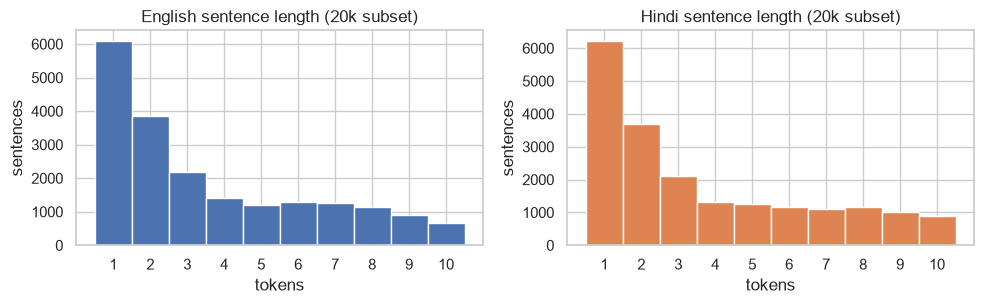

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (lang, idx) in zip(axes, (("English", 0), ("Hindi", 1))):
    lengths = [len(p[idx]) for p in subset]
    ax.hist(lengths, bins=np.arange(0.5, 11.5, 1), color="C0" if idx == 0 else "C1", edgecolor="white")
    ax.set(title=f"{lang} sentence length (20k subset)", xlabel="tokens", ylabel="sentences", xticks=range(1, 11))
plt.tight_layout()
plt.savefig(FIG_DIR / "length_hist.pdf", bbox_inches="tight")
plt.show()

**Reading the statistics.** One- and two-token pairs dominate the subset: the short end of the IITB
corpus consists largely of dictionary/glossary entries and software UI strings. Hindi has a
larger type inventory than English because it is morphologically richer (gender/number/case
inflection of nouns, adjectives and verbs: `गया/गई/गए`, `लड़का/लड़के`) and because loanwords appear in
several spellings (`फ़ाइल/फाइल`, `पहुंच/पहुँच`). Consequently the Hindi unknown-token rate on
held-out data is higher than the English one. Since about a quarter of reference tokens are
outside the target vocabulary, a part of every reference is simply impossible to reproduce, which
caps achievable BLEU.

In [8]:
def to_ids(pairs):
    return ([src_vocab.encode(e) + [EOS_IDX] for e, _ in pairs],          # source + <eos>
            [tgt_vocab.encode(h) + [EOS_IDX] for _, h in pairs])          # target + <eos>


ids = {k: to_ids(v) for k, v in splits.items()}
refs_tok = {k: [h for _, h in v] for k, v in splits.items()}  # original (non-<unk>) references


def pad_batch(seqs, pad=PAD_IDX):
    lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)
    out = torch.full((len(seqs), int(lengths.max())), pad, dtype=torch.long)
    for i, s in enumerate(seqs):
        out[i, :len(s)] = torch.tensor(s, dtype=torch.long)
    return out, lengths


def iterate_batches(split_ids, batch_size, shuffle=False, rng=None):
    """Yield (src, src_len, tgt_in, tgt_out) on DEVICE. tgt_in = <bos> y_1..y_n, tgt_out = y_1..y_n <eos>."""
    src_all, tgt_all = split_ids
    order = rng.permutation(len(src_all)) if shuffle else np.arange(len(src_all))
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        src, src_len = pad_batch([src_all[i] for i in idx])
        tgt, _ = pad_batch([tgt_all[i] for i in idx])
        tgt_in = torch.cat([torch.full((len(idx), 1), BOS_IDX, dtype=torch.long), tgt[:, :-1]], dim=1)
        tgt_in[tgt_in == EOS_IDX] = PAD_IDX  # the <eos> is never fed as an input token
        yield src.to(DEVICE), src_len.to(DEVICE), tgt_in.to(DEVICE), tgt.to(DEVICE)


src, src_len, tgt_in, tgt_out = next(iterate_batches(ids["train"], 3))
print("src", src.tolist(), "\nlen", src_len.tolist(), "\ntgt_in", tgt_in.tolist(), "\ntgt_out", tgt_out.tolist())

src [[3, 2, 0, 0, 0], [10, 3, 4512, 4, 2], [3, 2, 0, 0, 0]] 
len [2, 5, 2] 
tgt_in [[1, 3, 0, 0, 0], [1, 38, 3, 3, 18], [1, 3, 0, 0, 0]] 
tgt_out [[3, 2, 0, 0, 0], [38, 3, 3, 18, 2], [3, 2, 0, 0, 0]]


## 2. Task 1 — Recurrent cells and encoder–decoder translation

### 2.1 Cells from scratch

All three cells use only matrix products, additions, element-wise products, `sigmoid` and `tanh`.
Weight layout and gate order follow PyTorch (`W_ih` of shape `(G·H, d)`, `W_hh` of shape
`(G·H, H)`, two bias vectors; LSTM gates `i, f, g, o`; GRU gates `r, z, n`), which makes weight
copying for verification exact.

* **RNN:** $h_t = \tanh(W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh})$
* **LSTM:** $[i,f,g,o] = W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh}$;
  $c_t = \sigma(f)\odot c_{t-1} + \sigma(i)\odot\tanh(g)$; $h_t = \sigma(o)\odot\tanh(c_t)$
* **GRU:** $r = \sigma(W_{ir}x + b_{ir} + W_{hr}h + b_{hr})$, $z = \sigma(W_{iz}x + b_{iz} + W_{hz}h + b_{hz})$,
  $n = \tanh(W_{in}x + b_{in} + r\odot(W_{hn}h + b_{hn}))$, $h_t = (1-z)\odot n + z\odot h_{t-1}$

**Initialisation.** Every weight and bias is drawn i.i.d. from $\mathcal U(-1/\sqrt H, 1/\sqrt H)$
(the same scheme as PyTorch's recurrent layers), from the global torch generator that is seeded
immediately before a model is built. This keeps the pre-activations of each gate at unit-order scale
for $H$-dimensional states, so sigmoids/tanh start in their non-saturated region. We deliberately do
**not** add the common "forget-gate bias = 1" trick so that all three cells start from the same
distribution in the gradient-flow comparison.

**Padded batches.** `RecurrentLayer` runs a cell over time. With true lengths $L_b$, at a step
$t \ge L_b$ the state of sequence $b$ is *frozen* (`torch.where` copies the previous state) and its
output is set to zero. The returned final state is therefore the state after each sequence's own
last real token — exactly what `pack_padded_sequence` gives in PyTorch — and padding never leaks into
the state or the gradients.

In [9]:
class RNNCellScratch(nn.Module):
    """Elman RNN cell: h' = tanh(W_ih x + b_ih + W_hh h + b_hh)."""
    n_gates, has_cell_state = 1, False

    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size, self.hidden_size = input_size, hidden_size
        G = self.n_gates * hidden_size
        self.weight_ih = nn.Parameter(torch.empty(G, input_size))
        self.weight_hh = nn.Parameter(torch.empty(G, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(G))
        self.bias_hh = nn.Parameter(torch.empty(G))
        self.reset_parameters()

    def reset_parameters(self):
        k = 1.0 / math.sqrt(self.hidden_size)
        with torch.no_grad():
            for p in self.parameters():
                p.uniform_(-k, k)

    def init_state(self, batch_size, device, dtype):
        h = torch.zeros(batch_size, self.hidden_size, device=device, dtype=dtype)
        return (h, torch.zeros_like(h)) if self.has_cell_state else (h,)

    def forward(self, x, state):
        (h,) = state
        return (torch.tanh(x @ self.weight_ih.T + self.bias_ih + h @ self.weight_hh.T + self.bias_hh),)


class LSTMCellScratch(RNNCellScratch):
    """LSTM cell with input (i), forget (f), candidate (g) and output (o) gates."""
    n_gates, has_cell_state = 4, True

    def forward(self, x, state):
        h, c = state
        gates = x @ self.weight_ih.T + self.bias_ih + h @ self.weight_hh.T + self.bias_hh
        i, f, g, o = gates.chunk(4, dim=1)
        c_new = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h_new = torch.sigmoid(o) * torch.tanh(c_new)
        return (h_new, c_new)


class GRUCellScratch(RNNCellScratch):
    """GRU cell with reset (r), update (z) gates and candidate state (n)."""
    n_gates, has_cell_state = 3, False

    def forward(self, x, state):
        (h,) = state
        gi = x @ self.weight_ih.T + self.bias_ih
        gh = h @ self.weight_hh.T + self.bias_hh
        i_r, i_z, i_n = gi.chunk(3, dim=1)
        h_r, h_z, h_n = gh.chunk(3, dim=1)
        r = torch.sigmoid(i_r + h_r)
        z = torch.sigmoid(i_z + h_z)
        n = torch.tanh(i_n + r * h_n)   # reset gate acts on (W_hn h + b_hn), hence two biases
        return ((1 - z) * n + z * h,)


CELLS = {"rnn": RNNCellScratch, "lstm": LSTMCellScratch, "gru": GRUCellScratch}


class RecurrentLayer(nn.Module):
    """Runs a scratch cell over a (B, T, d) batch, respecting the true sequence lengths."""

    def __init__(self, cell_type, input_size, hidden_size):
        super().__init__()
        self.cell = CELLS[cell_type](input_size, hidden_size)

    def forward(self, x, lengths=None, state=None):
        B, T, _ = x.shape
        if state is None:
            state = self.cell.init_state(B, x.device, x.dtype)
        outputs = []
        for t in range(T):
            new_state = self.cell(x[:, t], state)
            if lengths is not None:
                valid = (lengths > t).unsqueeze(1)                       # (B, 1) bool
                new_state = tuple(torch.where(valid, n, s) for n, s in zip(new_state, state))
                outputs.append(torch.where(valid, new_state[0], torch.zeros_like(new_state[0])))
            else:
                outputs.append(new_state[0])
            state = new_state
        return torch.stack(outputs, dim=1), state


def n_params(module):
    return sum(p.numel() for p in module.parameters())

### 2.2 Verification against PyTorch's built-in layers

For each cell type we copy our weights into the corresponding PyTorch module and compare, in float64:

* single steps against `nn.RNNCell` / `nn.LSTMCell` / `nn.GRUCell`;
* a **padded batch with unequal lengths** (lengths 7, 5, 3, 1, 6) against `nn.RNN` / `nn.LSTM` /
  `nn.GRU` fed with `pack_padded_sequence`: all outputs (padded positions must be zero), final
  states, and the **gradients** of a random scalar loss w.r.t. the inputs and every weight.

*This is the only place where built-in recurrent layers are used.*

In [10]:
def verify_cell(cell_type, d=6, H=5, lengths=(7, 5, 3, 1, 6), seed=0):
    torch.manual_seed(seed)
    ours = RecurrentLayer(cell_type, d, H).double()
    cell = ours.cell
    builtin_cell = {"rnn": nn.RNNCell, "lstm": nn.LSTMCell, "gru": nn.GRUCell}[cell_type](d, H).double()
    builtin_layer = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell_type](d, H, batch_first=True).double()
    with torch.no_grad():
        for name in ("weight_ih", "weight_hh", "bias_ih", "bias_hh"):
            getattr(builtin_cell, name).copy_(getattr(cell, name))
            getattr(builtin_layer, name + "_l0").copy_(getattr(cell, name))

    B, T = len(lengths), max(lengths)
    lengths_t = torch.tensor(lengths)
    x = torch.randn(B, T, d, dtype=torch.float64)
    h0 = torch.randn(B, H, dtype=torch.float64)
    c0 = torch.randn(B, H, dtype=torch.float64)
    res = {"cell": cell_type}

    # (a) one step from a non-zero state
    st = (h0, c0) if cell.has_cell_state else (h0,)
    ref = builtin_cell(x[:, 0], st if cell.has_cell_state else h0)
    ref = ref if isinstance(ref, tuple) else (ref,)
    res["single step"] = max((a - b).abs().max().item() for a, b in zip(cell(x[:, 0], st), ref))

    # (b) full padded sequence, outputs + final state + gradients
    w_out = torch.randn(B, T, H, dtype=torch.float64)
    w_fin = torch.randn(B, H, dtype=torch.float64)

    x1 = x.clone().requires_grad_(True)
    out1, fin1 = ours(x1, lengths_t)
    (out1 * w_out).sum().backward(retain_graph=True)
    (fin1[0] * w_fin).sum().backward()

    x2 = x.clone().requires_grad_(True)
    packed = nn.utils.rnn.pack_padded_sequence(x2, lengths_t, batch_first=True, enforce_sorted=False)
    out2, fin2 = builtin_layer(packed)
    out2, _ = nn.utils.rnn.pad_packed_sequence(out2, batch_first=True, total_length=T)
    fin2 = fin2 if isinstance(fin2, tuple) else (fin2,)
    fin2 = tuple(f.squeeze(0) for f in fin2)
    (out2 * w_out).sum().backward(retain_graph=True)
    (fin2[0] * w_fin).sum().backward()

    res["outputs"] = (out1 - out2).abs().max().item()
    res["final state(s)"] = max((a - b).abs().max().item() for a, b in zip(fin1, fin2))
    res["padded outputs are 0"] = bool((out1[lengths_t.unsqueeze(1) <= torch.arange(T)] == 0).all())
    res["grad input"] = (x1.grad - x2.grad).abs().max().item()
    res["grad weights"] = max((getattr(cell, n).grad - getattr(builtin_layer, n + "_l0").grad).abs().max().item()
                              for n in ("weight_ih", "weight_hh", "bias_ih", "bias_hh"))
    return res


verification = pd.DataFrame([verify_cell(c) for c in ("rnn", "lstm", "gru")]).set_index("cell")
assert (verification.drop(columns="padded outputs are 0") < 1e-10).all().all()
assert verification["padded outputs are 0"].all()
print("max |ours - PyTorch| (float64); all checks passed")
verification

max |ours - PyTorch| (float64); all checks passed


,single step,outputs,final state(s),padded outputs are 0,grad input,grad weights
cell,,,,,,
rnn,1.110223e-16,1.110223e-16,1.110223e-16,True,2.220446e-16,3.552714e-15
lstm,2.220446e-16,5.551115e-17,1.110223e-16,True,1.110223e-16,5.551115e-16
gru,1.110223e-16,1.942890e-16,1.665335e-16,True,2.220446e-16,1.776357e-15


### 2.3 Parameter count for $d = 128$, $H = 256$

With PyTorch's two-bias layout a cell with $G$ gate blocks has $G\,(dH + H^2 + 2H)$ parameters:
RNN $G=1$, GRU $G=3$, LSTM $G=4$.

In [11]:
d, H = 128, 256
pc = pd.DataFrame([{"cell": c.upper(), "gates G": CELLS[c].n_gates,
                    "formula G(dH+H^2+2H)": CELLS[c].n_gates * (d * H + H * H + 2 * H),
                    "counted": n_params(CELLS[c](d, H))} for c in ("rnn", "lstm", "gru")]).set_index("cell")
assert (pc["formula G(dH+H^2+2H)"] == pc["counted"]).all()
print(f"LSTM / GRU = {pc.loc['LSTM', 'counted'] / pc.loc['GRU', 'counted']:.4f}")
pc

LSTM / GRU = 1.3333


,gates G,formula G(dH+H^2+2H),counted
cell,,,
RNN,1,98816,98816
LSTM,4,395264,395264
GRU,3,296448,296448


**LSTM/GRU ratio = 4/3 exactly.** Each gate block (input-to-hidden matrix, hidden-to-hidden matrix
and the two biases) has the same size $dH + H^2 + 2H$ in both cells. The LSTM has four blocks
(input, forget, output gates and the cell candidate) while the GRU has three (reset, update gates
and the candidate): the GRU merges the input and forget gates into one update gate $z$ (using
$z$ and $1-z$) and has no separate cell state and therefore no output gate. Hence
395,264 / 296,448 = 4/3, independently of $d$ and $H$. (The two-bias convention is required for the
GRU because $b_{hn}$ sits inside the reset-gate product; for the LSTM the two biases are redundant
but kept for compatibility with PyTorch.)

### 2.4 Gradient flow: vanilla RNN vs LSTM vs GRU

For $T \in \{10, 25, 50, 100\}$, $B=16$, $d=32$, $H=64$ and inputs $x \sim \mathcal N(0, I)$ we
compute $\big\|\partial \|h_T\|_2^2 / \partial x_1\big\|_2$ per sequence, average over the batch and
then over seeds 0–4. For seed $s$, the cell is initialised after `torch.manual_seed(s)` and the inputs
come from a separate generator seeded with $s$, so all three cells see identical inputs. Because the
sequences in a batch are independent, back-propagating the batch sum $\sum_b \|h_T^{(b)}\|^2$ gives
each sequence's own gradient. Computation is in float64 on CPU to avoid underflow.

In [12]:
def grad_profile(cell_type, T, seed, B=16, d=32, H=64):
    """Return mean_b ||d||h_T||^2 / dx_t|| for every t = 1..T."""
    torch.manual_seed(seed)
    layer = RecurrentLayer(cell_type, d, H).double()
    gen = torch.Generator().manual_seed(seed)
    x = torch.randn(B, T, d, generator=gen, dtype=torch.float64).requires_grad_(True)
    _, state = layer(x)
    (state[0] ** 2).sum().backward()
    return x.grad.norm(dim=2).mean(dim=0).numpy()    # (T,)


T_VALUES, GRAD_SEEDS = [10, 25, 50, 100], range(5)
grad_rows, profiles = [], {}
for cell_type in ("rnn", "lstm", "gru"):
    for T in T_VALUES:
        per_seed = [grad_profile(cell_type, T, s) for s in GRAD_SEEDS]
        if T == 100:
            profiles[cell_type] = np.mean(per_seed, axis=0)
        first = [p[0] for p in per_seed]
        grad_rows.append({"cell": cell_type.upper(), "T": T, "mean grad norm": np.mean(first),
                          "std over seeds": np.std(first)})
grad_df = pd.DataFrame(grad_rows)
grad_table = grad_df.pivot(index="T", columns="cell", values="mean grad norm")[["RNN", "LSTM", "GRU"]]
grad_table.style.format("{:.3e}")

cell,RNN,LSTM,GRU
T,,,
10,2.799e-03,1.359e-03,5.980e-03
25,5.848e-08,7.939e-07,4.496e-06
50,1.534e-15,4.333e-12,5.170e-11
100,2.066e-30,1.220e-22,9.649e-21


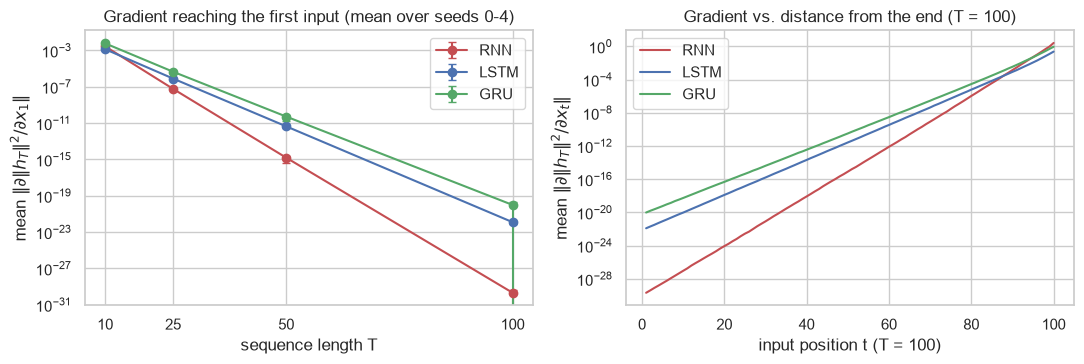

average per-step backward gradient factor (T = 100 profile): {'RNN': 0.499, 'LSTM': 0.613, 'GRU': 0.634}


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for cell_type, color in zip(("RNN", "LSTM", "GRU"), ("C3", "C0", "C2")):
    sub = grad_df[grad_df.cell == cell_type]
    axes[0].errorbar(sub["T"], sub["mean grad norm"], yerr=sub["std over seeds"], marker="o",
                     color=color, label=cell_type, capsize=3)
    axes[1].plot(np.arange(1, 101), profiles[cell_type.lower()], color=color, label=cell_type)
axes[0].set(yscale="log", xlabel="sequence length T", ylabel=r"mean $\|\partial\|h_T\|^2/\partial x_1\|$",
            title="Gradient reaching the first input (mean over seeds 0-4)", xticks=T_VALUES)
axes[1].set(yscale="log", xlabel="input position t (T = 100)", ylabel=r"mean $\|\partial\|h_T\|^2/\partial x_t\|$",
            title="Gradient vs. distance from the end (T = 100)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "gradient_flow.pdf", bbox_inches="tight")
plt.show()

# Slope of log-gradient vs position t: going one step further back in time multiplies the gradient by exp(-slope).
slopes = {c: np.polyfit(np.arange(1, 101), np.log(profiles[c]), 1)[0] for c in profiles}
decay_factor = {c.upper(): float(np.exp(-s)) for c, s in slopes.items()}
print("average per-step backward gradient factor (T = 100 profile):", {c: round(v, 3) for c, v in decay_factor.items()})

**Observation.** All three curves fall almost *linearly on the log scale*: the gradient reaching $x_1$
decays **exponentially** in $T$, because it is a product of $T-1$ step Jacobians
$\partial h_t/\partial h_{t-1}$ (right panel: a straight line, the fitted average per-step factor is
printed above: RNN ≈ 0.50, LSTM ≈ 0.61, GRU ≈ 0.63).

* **Vanilla RNN** — fastest decay (≈ 2.8e-3 at $T=10$ but ≈ 2e-30 at $T=100$). Each Jacobian is
  $\mathrm{diag}(1-h_t^2)\,W_{hh}$; with the $\mathcal U(\pm1/\sqrt H)$ initialisation the spectral
  radius of $W_{hh}$ is ≈ $1/\sqrt3 \approx 0.58$ and $\tanh' \le 1$, so every step multiplies the
  gradient by roughly one half. After 25 steps essentially nothing of $x_1$ can influence learning.
* **LSTM** — at $T=10$ its gradient is actually *smaller* than the RNN's (the output gate and the
  extra $\tanh(c_t)$ each scale $h_T$ by ≈ 0.5 at initialisation), but it decays more slowly and is
  ~8 orders of magnitude larger than the RNN's at $T=100$. The cell state has an *additive* path
  $c_t = f_t\odot c_{t-1} + \dots$ whose Jacobian is just $\mathrm{diag}(f_t)$ — no weight matrix and no
  squashing non-linearity on that path.
* **GRU** — largest gradient at every $T$. $h_t = z_t\odot h_{t-1} + (1-z_t)\odot n_t$ is a gated
  identity path with factor $z_t$, plus a contribution through $n_t$, and there is no output gate.

At initialisation all gates sit near $\sigma(0)=0.5$, so the gated cells *also* decay
exponentially — gating is not a guarantee against vanishing gradients. The essential difference is
that their per-step factor is a **learnable, input-dependent gate** that training can push towards 1
to carry information over long spans (e.g. a forget-gate bias of +1 would already give
$\sigma(1)=0.73$ per step), while the RNN's factor is fixed by $W_{hh}$ and the tanh saturation.

### 2.5 Corpus-level BLEU-4 (own implementation) and sacrebleu

$\mathrm{BLEU} = \mathrm{BP}\cdot\exp\big(\tfrac14\sum_{n=1}^4 \log p_n\big)$ with corpus-level
clipped $n$-gram precisions $p_n = \sum_s \sum_g \min(c_{hyp}(g), c_{ref}(g)) / \sum_s \max(|h_s|-n+1, 0)$
and brevity penalty $\mathrm{BP} = \min(1, e^{1-r/c})$ (total reference length $r$, total hypothesis
length $c$). The counts are summed over the corpus **before** dividing (corpus BLEU, not the
average of sentence BLEUs). Optional NIST "exp" smoothing (the sacrebleu default) replaces the $k$-th
zero precision by $1/(2^k\,\text{total}_n)$; with thousands of sentences it is practically never
triggered.

In [14]:
def ngram_counts(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))


def corpus_bleu4(hypotheses, references, smooth="exp", max_n=4):
    """Corpus BLEU-4 (x100) for tokenised hypotheses/references (one reference per sentence)."""
    correct, total = [0] * max_n, [0] * max_n
    hyp_len = ref_len = 0
    for hyp, ref in zip(hypotheses, references):
        hyp_len += len(hyp)
        ref_len += len(ref)
        for n in range(1, max_n + 1):
            ref_ngrams = ngram_counts(ref, n)
            correct[n - 1] += sum(min(c, ref_ngrams[g]) for g, c in ngram_counts(hyp, n).items())
            total[n - 1] += max(len(hyp) - n + 1, 0)
    if hyp_len == 0 or not any(correct):
        return 0.0
    bp = 1.0 if hyp_len >= ref_len else math.exp(1 - ref_len / hyp_len)
    log_p, n_zero = 0.0, 0
    for c, t in zip(correct, total):
        if t == 0:                         # no n-grams of this order at all
            return 0.0
        if c == 0:
            if smooth != "exp":
                return 0.0
            n_zero += 1
            log_p += math.log(1 / (2 ** n_zero * t))
        else:
            log_p += math.log(c / t)
    return 100 * bp * math.exp(log_p / max_n)


def sacre_bleu(hypotheses, references, smooth="exp"):
    """sacrebleu on the *same* pre-tokenised strings (tokenize='none')."""
    return sacrebleu.corpus_bleu([" ".join(h) for h in hypotheses], [[" ".join(r) for r in references]],
                                 tokenize="none", smooth_method=smooth, force=True).score


# Sanity checks on random Hindi-like corpora: our BLEU must equal sacrebleu's.
rng_bleu = np.random.default_rng(0)
words = tgt_vocab.itos[4:200]
max_diff = 0.0
for trial in range(200):
    refs = [list(rng_bleu.choice(words, rng_bleu.integers(1, 11))) for _ in range(30)]
    hyps = [[w if rng_bleu.random() < 0.6 else rng_bleu.choice(words) for w in r][: rng_bleu.integers(1, 12)]
            for r in refs]
    for smooth in ("exp", "none"):
        max_diff = max(max_diff, abs(corpus_bleu4(hyps, refs, smooth) - sacre_bleu(hyps, refs, smooth)))
print(f"max |own - sacrebleu| over 400 random corpora: {max_diff:.2e}")
assert max_diff < 1e-9

max |own - sacrebleu| over 400 random corpora: 1.42e-14


**Why BLEU under-rewards valid Hindi translations — a constructed example.** Hindi word order is
relatively free because grammatical roles are marked by postpositions (`ने`, `को`, `से`, `में`), not
position. Swapping the two arguments below keeps the meaning identical but destroys most 3- and
4-grams. Synonyms (`किताब`/`पुस्तक`) and spelling variants (`गई`/`गयी`) are also scored as errors.

In [15]:
ref = "राम ने सीता को किताब दी ।".split()
variants = {
    "identical": "राम ने सीता को किताब दी ।",
    "arguments swapped (same meaning)": "सीता को राम ने किताब दी ।",
    "synonym किताब -> पुस्तक": "राम ने सीता को पुस्तक दी ।",
    "wrong meaning (Sita gave Ram)": "सीता ने राम को किताब दी ।",
}
pd.DataFrame([{"hypothesis": v, "BLEU-4 (own)": corpus_bleu4([v.split()], [ref]),
               "sacrebleu": sacre_bleu([v.split()], [ref])} for v in variants.values()],
             index=variants.keys()).round(2)

,hypothesis,BLEU-4 (own),sacrebleu
identical,राम ने सीता को किताब दी ।,100.00,100.00
arguments swapped (same meaning),सीता को राम ने किताब दी ।,35.93,35.93
synonym किताब -> पुस्तक,राम ने सीता को पुस्तक दी ।,48.89,48.89
wrong meaning (Sita gave Ram),सीता ने राम को किताब दी ।,47.29,47.29


The meaning-preserving reordering scores *lower* than the sentence whose meaning is reversed
(agent and recipient exchanged), because BLEU only counts surface n-gram overlap with a single reference.

### 2.6 Configurable encoder–decoder

* **Encoder:** embedding → `num_layers` × `RecurrentLayer` (LSTM or GRU, our cells), run over the true
  source lengths. Its final state (both $h$ and $c$ for the LSTM) after the last real source token is
  the *only* information passed to the decoder — a fixed-size summary, no attention.
* **Decoder:** embedding → the same cell type, initialised with the encoder's final state(s), →
  dropout → linear projection to the Hindi vocabulary.
* **Training — teacher forcing:** the decoder input at step $t$ is the *reference* token $y_{t-1}$
  (`<bos>` at $t=1$); the loss is the token-level cross-entropy over all non-padding target positions
  (including `<eos>`).
* **Inference — greedy free-running decoding:** starting from `<bos>`, feed back the arg-max token,
  stop when every sentence has produced `<eos>` or after **20 steps**.

Configurable: `cell_type`, `emb_dim`, `hidden_size`, `num_layers`, `dropout`.

In [16]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_size, cell_type, num_layers=1, dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.layers = nn.ModuleList([RecurrentLayer(cell_type, emb_dim if l == 0 else hidden_size, hidden_size)
                                     for l in range(num_layers)])
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_len):
        x = self.dropout(self.embedding(src))
        states = []
        for l, layer in enumerate(self.layers):
            x, state = layer(x, src_len)
            states.append(state)
            if l < len(self.layers) - 1:
                x = self.dropout(x)
        return states                       # one state tuple per layer


class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_size, cell_type, num_layers=1, dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.cells = nn.ModuleList([CELLS[cell_type](emb_dim if l == 0 else hidden_size, hidden_size)
                                    for l in range(num_layers)])
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(hidden_size, vocab_size)

    def step(self, tokens, states):
        """One decoding step: tokens (B,) -> logits (B, V), new states."""
        x = self.dropout(self.embedding(tokens))
        new_states = []
        for l, cell in enumerate(self.cells):
            state = cell(x, states[l])
            new_states.append(state)
            x = self.dropout(state[0])
        return self.out(x), new_states

    def forward(self, tgt_in, states):
        """Teacher forcing: the reference prefix is fed at every step."""
        logits = []
        for t in range(tgt_in.size(1)):
            step_logits, states = self.step(tgt_in[:, t], states)
            logits.append(step_logits)
        return torch.stack(logits, dim=1)   # (B, T, V)


class Seq2Seq(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, cell_type="lstm", emb_dim=128, hidden_size=128,
                 num_layers=1, dropout=0.3):
        super().__init__()
        self.config = dict(cell_type=cell_type, emb_dim=emb_dim, hidden_size=hidden_size,
                           num_layers=num_layers, dropout=dropout)
        self.encoder = Encoder(src_vocab_size, emb_dim, hidden_size, cell_type, num_layers, dropout)
        self.decoder = Decoder(tgt_vocab_size, emb_dim, hidden_size, cell_type, num_layers, dropout)

    def forward(self, src, src_len, tgt_in):
        return self.decoder(tgt_in, self.encoder(src, src_len))

    @torch.no_grad()
    def greedy_decode(self, src, src_len, max_len=20):
        """Free-running greedy decoding; returns (B, <=max_len) token ids (incl. <eos> if produced)."""
        states = self.encoder(src, src_len)
        tokens = torch.full((src.size(0),), BOS_IDX, dtype=torch.long, device=src.device)
        finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
        outputs = []
        for _ in range(max_len):
            logits, states = self.decoder.step(tokens, states)
            tokens = logits.argmax(dim=-1)
            outputs.append(tokens)
            finished |= tokens == EOS_IDX
            if finished.all():
                break
        return torch.stack(outputs, dim=1)

### 2.7 Training loop and metrics

* **loss** = mean token cross-entropy over non-pad target tokens (teacher forcing);
  **perplexity** = $\exp(\text{loss})$; **token accuracy** = fraction of non-pad target positions whose
  arg-max prediction equals the reference token (also under teacher forcing).
* **validation BLEU-4**: greedy decoding (≤ 20 steps) of the whole validation set, scored against the
  original tokenised references (OOV reference words are *not* replaced by `<unk>`, so `<unk>` in an
  output never matches). Both our BLEU and sacrebleu are logged; **sacrebleu is used for selection**.
* **checkpoint** = the earliest epoch with the maximum validation sacreBLEU (strict `>` comparison).
* Training metrics are accumulated during the epoch (with dropout active).

In [17]:
HPARAMS = dict(emb_dim=128, num_layers=1, dropout=0.3, lr=3e-3, batch_size=64, epochs=10, grad_clip=1.0,
               max_decode_len=20, eval_batch_size=500, min_freq=MIN_FREQ, optimizer="Adam (betas 0.9, 0.999)")


def run_epoch(model, split_ids, optimizer=None, rng=None, batch_size=64, grad_clip=1.0):
    """One pass over a split. Trains if an optimizer is given; returns loss, perplexity, token accuracy."""
    training = optimizer is not None
    model.train(training)
    loss_sum, n_tok, n_correct = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for src, src_len, tgt_in, tgt_out in iterate_batches(split_ids, batch_size, shuffle=training, rng=rng):
            logits = model(src, src_len, tgt_in)
            mask = tgt_out != PAD_IDX
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1),
                                   ignore_index=PAD_IDX, reduction="sum")
            tokens = int(mask.sum())
            if training:
                optimizer.zero_grad(set_to_none=True)
                (loss / tokens).backward()
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.step()
            loss_sum += loss.item()
            n_tok += tokens
            n_correct += int(((logits.argmax(-1) == tgt_out) & mask).sum())
    mean_loss = loss_sum / n_tok
    return {"loss": mean_loss, "ppl": math.exp(mean_loss), "acc": n_correct / n_tok}


def translate(model, split_ids, max_len=20, batch_size=500):
    """Greedy translations (token lists) for a whole split, in order."""
    model.eval()
    hyps = []
    for src, src_len, _, _ in iterate_batches(split_ids, batch_size):
        for row in model.greedy_decode(src, src_len, max_len).tolist():
            hyps.append(tgt_vocab.decode(row))
    return hyps


def bleu_scores(model, split):
    hyps = translate(model, ids[split], HPARAMS["max_decode_len"], HPARAMS["eval_batch_size"])
    return {"bleu_sacre": sacre_bleu(hyps, refs_tok[split]),
            "bleu_own": corpus_bleu4(hyps, refs_tok[split])}, hyps


def build_model(cell_type, hidden_size, seed):
    set_seed(seed)  # identical initialisation stream for every configuration
    return Seq2Seq(len(src_vocab), len(tgt_vocab), cell_type, HPARAMS["emb_dim"], hidden_size,
                   HPARAMS["num_layers"], HPARAMS["dropout"]).to(DEVICE)


def train_model(cell_type, hidden_size, seed=SEED, verbose=True):
    name = f"{cell_type.upper()}-{hidden_size}"
    model = build_model(cell_type, hidden_size, seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=HPARAMS["lr"])
    rng = np.random.default_rng(seed)  # shuffling order (same for every configuration)
    history, best = [], {"bleu": -1.0}
    train_time = 0.0
    for epoch in range(1, HPARAMS["epochs"] + 1):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        tr = run_epoch(model, ids["train"], optimizer, rng, HPARAMS["batch_size"], HPARAMS["grad_clip"])
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.perf_counter() - t0
        train_time += epoch_time
        va = run_epoch(model, ids["val"], batch_size=HPARAMS["eval_batch_size"])
        bleu, _ = bleu_scores(model, "val")
        row = {"epoch": epoch, **{f"train_{k}": v for k, v in tr.items()}, **{f"val_{k}": v for k, v in va.items()},
               "val_bleu_sacre": bleu["bleu_sacre"], "val_bleu_own": bleu["bleu_own"], "epoch_train_time_s": epoch_time}
        history.append(row)
        if bleu["bleu_sacre"] > best["bleu"]:          # strict '>' keeps the earliest best epoch
            best = {"bleu": bleu["bleu_sacre"], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        if verbose:
            print(f"{name} ep{epoch:2d} | train loss {tr['loss']:.3f} acc {tr['acc']:.3f} | val loss {va['loss']:.3f} "
                  f"ppl {va['ppl']:.1f} acc {va['acc']:.3f} | BLEU sacre {bleu['bleu_sacre']:.2f} own "
                  f"{bleu['bleu_own']:.2f} | {epoch_time:.1f}s")
    model.load_state_dict(best["state"])
    return {"name": name, "cell": cell_type, "hidden": hidden_size, "seed": seed, "params": n_params(model),
            "train_time_s": train_time, "best_epoch": best["epoch"], "history": pd.DataFrame(history),
            "model": model}

## 3. Task 2 — Cell type and hidden size

Four runs (LSTM-64, GRU-64, LSTM-128, GRU-128). Everything else is fixed:

In [18]:
pd.Series(HPARAMS, name="value").to_frame()

,value
emb_dim,128
num_layers,1
dropout,0.3
lr,0.003
batch_size,64
epochs,10
grad_clip,1.0
max_decode_len,20
eval_batch_size,500
min_freq,2


In [19]:
CONFIGS = [("lstm", 64), ("gru", 64), ("lstm", 128), ("gru", 128)]   # also the tie-break order
runs = {}
for cell_type, hidden in CONFIGS:
    run = train_model(cell_type, hidden, SEED)
    runs[run["name"]] = run
    torch.save({"state_dict": run["model"].state_dict(), "config": run["model"].config, "best_epoch": run["best_epoch"]},
               CKPT_DIR / f"{run['name']}.pt")
    print()

LSTM-64 ep 1 | train loss 5.288 acc 0.318 | val loss 4.262 ppl 70.9 acc 0.393 | BLEU sacre 0.07 own 0.07 | 12.1s


LSTM-64 ep 2 | train loss 4.668 acc 0.360 | val loss 4.105 ppl 60.6 acc 0.404 | BLEU sacre 0.14 own 0.14 | 11.4s


LSTM-64 ep 3 | train loss 4.463 acc 0.371 | val loss 3.987 ppl 53.9 acc 0.416 | BLEU sacre 0.15 own 0.15 | 11.8s


LSTM-64 ep 4 | train loss 4.311 acc 0.380 | val loss 3.911 ppl 49.9 acc 0.421 | BLEU sacre 0.25 own 0.25 | 11.6s


LSTM-64 ep 5 | train loss 4.163 acc 0.389 | val loss 3.850 ppl 47.0 acc 0.428 | BLEU sacre 0.37 own 0.37 | 11.4s


LSTM-64 ep 6 | train loss 4.031 acc 0.398 | val loss 3.803 ppl 44.8 acc 0.432 | BLEU sacre 0.50 own 0.50 | 11.9s


... (30 outputs left out)

GRU-128 ep 7 | train loss 3.053 acc 0.455 | val loss 3.460 ppl 31.8 acc 0.469 | BLEU sacre 2.22 own 2.22 | 12.9s


GRU-128 ep 8 | train loss 2.903 acc 0.467 | val loss 3.435 ppl 31.0 acc 0.468 | BLEU sacre 2.39 own 2.39 | 12.7s


GRU-128 ep 9 | train loss 2.758 acc 0.478 | val loss 3.437 ppl 31.1 acc 0.470 | BLEU sacre 2.26 own 2.26 | 12.8s


GRU-128 ep10 | train loss 2.634 acc 0.491 | val loss 3.446 ppl 31.4 acc 0.473 | BLEU sacre 2.56 own 2.56 | 12.9s



In [20]:
def summary_row(run):
    h = run["history"].set_index("epoch")
    ck = h.loc[run["best_epoch"]]
    return {"model": run["name"], "params": run["params"], "train time (s)": run["train_time_s"],
            "ckpt epoch": run["best_epoch"], "val BLEU sacre": ck["val_bleu_sacre"], "val BLEU own": ck["val_bleu_own"],
            "val loss": ck["val_loss"], "val ppl": ck["val_ppl"], "val acc": ck["val_acc"],
            "train loss": ck["train_loss"], "train acc": ck["train_acc"],
            "min val loss epoch": int(h["val_loss"].idxmin()), "min val loss": h["val_loss"].min()}


summary = pd.DataFrame([summary_row(r) for r in runs.values()]).set_index("model")
summary.round(3)

,params,train time (s),ckpt epoch,val BLEU sacre,val BLEU own,val loss,val ppl,val acc,train loss,train acc,min val loss epoch,min val loss
model,,,,,,,,,,,,
LSTM-64,1686382,124.122,9,1.511,1.511,3.718,41.183,0.443,3.719,0.414,10,3.709
GRU-64,1661550,130.074,8,1.497,1.497,3.603,36.716,0.452,3.621,0.420,10,3.578
LSTM-128,2169582,129.679,8,1.653,1.653,3.621,37.385,0.461,3.325,0.440,10,3.617
GRU-128,2103534,129.792,10,2.561,2.561,3.446,31.370,0.473,2.634,0.491,8,3.435


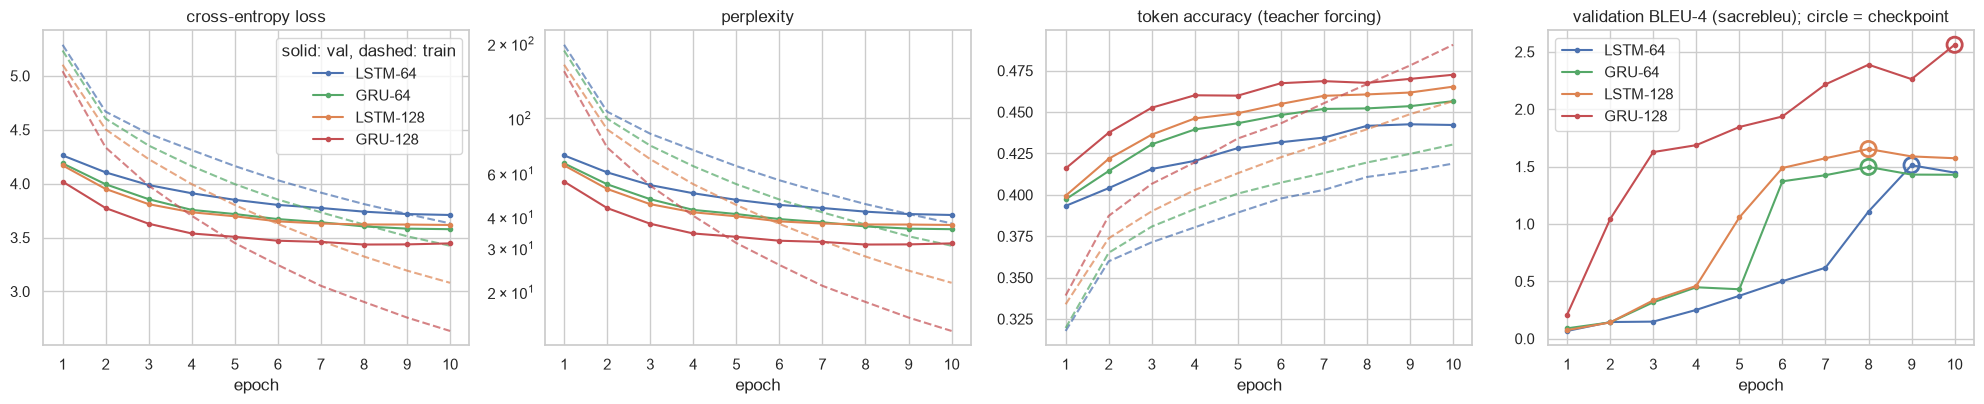

In [21]:
metrics = [("loss", "cross-entropy loss"), ("ppl", "perplexity"), ("acc", "token accuracy (teacher forcing)")]
colors = dict(zip(runs, ("C0", "C2", "C1", "C3")))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for name, run in runs.items():
    h = run["history"]
    for ax, (m, label) in zip(axes[:3], metrics):
        ax.plot(h.epoch, h[f"train_{m}"], "--", color=colors[name], alpha=0.7)
        ax.plot(h.epoch, h[f"val_{m}"], "-o", ms=3, color=colors[name], label=name)
        ax.set(xlabel="epoch", title=label)
    axes[3].plot(h.epoch, h.val_bleu_sacre, "-o", ms=3, color=colors[name], label=name)
    axes[3].scatter([run["best_epoch"]], [h.val_bleu_sacre[run["best_epoch"] - 1]], s=120, facecolors="none",
                    edgecolors=colors[name], linewidths=2)
axes[1].set_yscale("log")
axes[3].set(xlabel="epoch", title="validation BLEU-4 (sacrebleu); circle = checkpoint")
axes[0].legend(title="solid: val, dashed: train")
axes[3].legend()
for ax in axes:
    ax.set_xticks(range(1, HPARAMS["epochs"] + 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "training_curves.pdf", bbox_inches="tight")
plt.show()

Per-run curves (one panel per run) are shown below for completeness, with loss on the left axis and
validation BLEU on the right axis, which makes the loss-vs-BLEU checkpoint question easy to read.

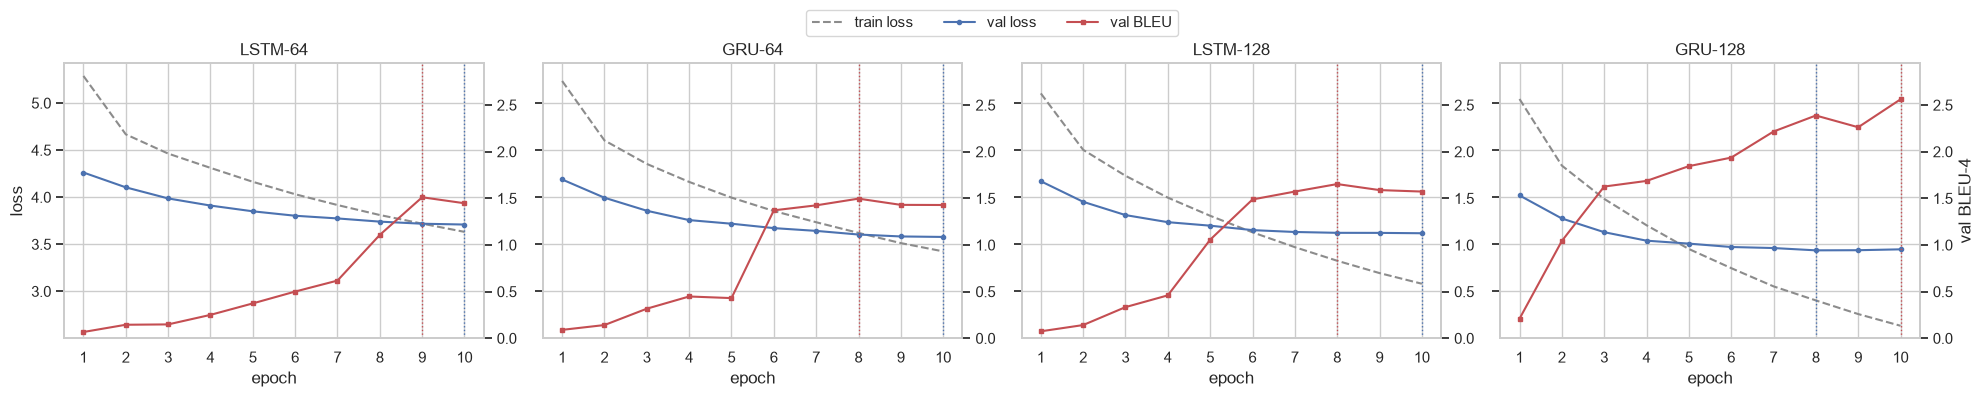

LSTM-64: min val loss at epoch 10 | max val BLEU at epoch 9 | Spearman(val loss, val BLEU) = -0.99
GRU-64: min val loss at epoch 10 | max val BLEU at epoch 8 | Spearman(val loss, val BLEU) = -0.94
LSTM-128: min val loss at epoch 10 | max val BLEU at epoch 8 | Spearman(val loss, val BLEU) = -0.95
GRU-128: min val loss at epoch 8 | max val BLEU at epoch 10 | Spearman(val loss, val BLEU) = -0.96


In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, (name, run) in zip(axes, runs.items()):
    h = run["history"]
    ax.plot(h.epoch, h.train_loss, "--", color="C7", label="train loss")
    ax.plot(h.epoch, h.val_loss, "-o", ms=3, color="C0", label="val loss")
    ax.axvline(h.val_loss.idxmin() + 1, color="C0", ls=":", lw=1)
    ax2 = ax.twinx()
    ax2.plot(h.epoch, h.val_bleu_sacre, "-s", ms=3, color="C3", label="val BLEU")
    ax2.axvline(run["best_epoch"], color="C3", ls=":", lw=1)
    ax2.set_ylim(0, max(r["history"].val_bleu_sacre.max() for r in runs.values()) * 1.15)
    ax.set(title=name, xlabel="epoch", xticks=range(1, 11))
    if ax is axes[0]:
        ax.set_ylabel("loss")
    if ax is axes[-1]:
        ax2.set_ylabel("val BLEU-4")
    ax2.grid(False)
h1, l1 = axes[0].get_legend_handles_labels()
fig.legend(h1 + ax2.get_legend_handles_labels()[0], l1 + ["val BLEU"], loc="upper center", ncol=3,
           bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
plt.savefig(FIG_DIR / "loss_vs_bleu.pdf", bbox_inches="tight")
plt.show()

for name, run in runs.items():
    h = run["history"]
    print(f"{name}: min val loss at epoch {h.val_loss.idxmin() + 1} | max val BLEU at epoch {run['best_epoch']} | "
          f"Spearman(val loss, val BLEU) = {h.val_loss.rank().corr(h.val_bleu_sacre.rank()):.2f}")

In [23]:
pd.concat({n: r["history"].set_index("epoch") for n, r in runs.items()}, names=["model"]).round(3)

train_loss  train_ppl  train_acc  val_loss  val_ppl  val_acc  \
model    epoch                                                                 
LSTM-64  1           5.288    197.897      0.318     4.262   70.946    0.393   
         2           4.668    106.436      0.360     4.105   60.614    0.404   
         3           4.463     86.766      0.371     3.987   53.880    0.416   
         4           4.311     74.531      0.380     3.911   49.945    0.421   
         5           4.163     64.280      0.389     3.850   46.988    0.428   
         6           4.031     56.340      0.398     3.803   44.822    0.432   
         7           3.917     50.228      0.403     3.774   43.563    0.435   
         8           3.810     45.172      0.411     3.740   42.109    0.442   
         9           3.719     41.215      0.414     3.718   41.183    0.443   
         10          3.631     37.767      0.419     3.709   40.826    0.442   
GRU-64   1           5.234    187.626      0.320     4.188   65.889    0.397   
         2           4.603     99.766      0.365     3.994   54.283    0.414   
         3           4.353     77.739      0.381     3.856   47.266    0.431   
         4           4.162     64.206      0.391     3.756   42.798    0.439   
         5           3.995     54.346      0.401     3.718   41.184    0.443   
         6           3.853     47.133      0.407     3.671   39.306    0.448   
         7           3.734     41.842      0.413     3.642   38.165    0.452   
         8           3.621     37.361      0.420     3.603   36.716    0.452   
         9           3.512     33.519      0.425     3.583   35.974    0.454   
         10          3.424     30.696      0.430     3.578   35.788    0.457   
LSTM-128 1           5.103    164.444      0.334     4.169   64.672    0.399   
         2           4.503     90.307      0.374     3.951   51.985    0.422   
         3           4.227     68.524      0.390     3.810   45.138    0.436   
         4           3.995     54.333      0.403     3.734   41.866    0.446   
         5           3.802     44.806      0.413     3.697   40.337    0.449   
         6           3.627     37.584      0.423     3.650   38.478    0.455   
         7           3.469     32.106      0.431     3.630   37.722    0.460   
         8           3.325     27.786      0.440     3.621   37.385    0.461   
         9           3.194     24.374      0.449     3.621   37.363    0.462   
         10          3.080     21.768      0.457     3.617   37.219    0.465   
GRU-128  1           5.043    154.919      0.339     4.019   55.634    0.416   
         2           4.336     76.364      0.387     3.774   43.537    0.438   
         3           3.982     53.632      0.407     3.628   37.644    0.453   
         4           3.702     40.525      0.420     3.538   34.395    0.460   
         5           3.449     31.484      0.434     3.507   33.338    0.460   
         6           3.246     25.694      0.443     3.471   32.159    0.467   
         7           3.053     21.168      0.455     3.460   31.807    0.469   
         8           2.903     18.231      0.467     3.435   31.037    0.468   
         9           2.758     15.773      0.478     3.437   31.083    0.470   
         10          2.634     13.927      0.491     3.446   31.370    0.473   

                val_bleu_sacre  val_bleu_own  epoch_train_time_s  
model    epoch                                                    
LSTM-64  1               0.067         0.067              12.060  
         2               0.145         0.145              11.385  
         3               0.149         0.149              11.848  
         4               0.251         0.251              11.618  
         5               0.374         0.374              11.372  
         6               0.501         0.501              11.873  
         7               0.618         0.618              12.467  
         8               1.108         1.108        

## 4. Task 3 — Final model

### 4.1 Selection
Highest checkpoint validation sacreBLEU; ties broken by fewer parameters, then by the order
LSTM-64, GRU-64, LSTM-128, GRU-128. (Scores are compared after rounding to 2 decimals, the precision at which
BLEU is reported, so that numerically indistinguishable scores count as ties.)

In [24]:
ORDER = [f"{c.upper()}-{h}" for c, h in CONFIGS]
ranking = sorted(runs, key=lambda n: (-round(summary.loc[n, "val BLEU sacre"], 2), runs[n]["params"], ORDER.index(n)))
FINAL = ranking[0]
final_model = runs[FINAL]["model"]
print("ranking by validation sacreBLEU:", ranking)
print("selected final model:", FINAL)

ranking by validation sacreBLEU: ['GRU-128', 'LSTM-128', 'LSTM-64', 'GRU-64']
selected final model: GRU-128


**Justification.** GRU-128 has the highest checkpoint validation sacreBLEU (2.56 vs ≤ 1.65), so no
tie-break is needed. It also has the lowest validation loss/perplexity and highest token accuracy of
all four runs, so every validation metric agrees. It has fewer parameters than LSTM-128 (2.10 M vs
2.17 M; only 0.42 M more than the 64-unit models), trains no slower than the others, and Section 5
shows that its first place is stable across seeds. Its checkpoint is epoch 10, the last allowed epoch.

### 4.2 Teacher forcing vs free-running decoding (validation set, final model)

Under **teacher forcing** the decoder is always conditioned on the *reference* prefix
$y_{<t}$; at test time (**free running**) it is conditioned on its *own* previous predictions
$\hat y_{<t}$. The model never sees its own mistakes during training (*exposure bias*), so one wrong
token puts the decoder in a state distribution it was not trained on and errors compound. Below we
measure position-wise accuracy under both regimes and show concrete Hindi examples.

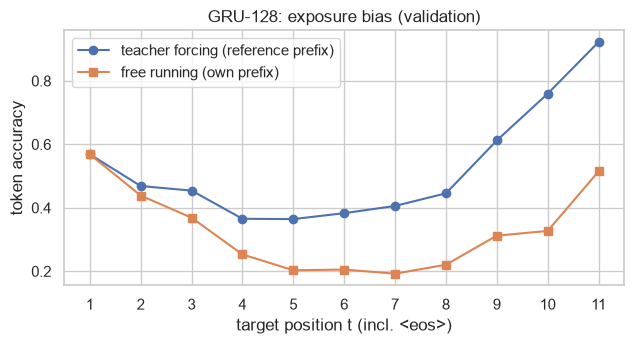

,position,targets,teacher forcing acc,free running acc
0,1,2000,0.568,0.568
1,2,2000,0.468,0.438
2,3,1416,0.454,0.369
3,4,1024,0.365,0.253
4,5,818,0.364,0.203
5,6,692,0.383,0.205
6,7,562,0.406,0.192
7,8,440,0.445,0.220
8,9,330,0.612,0.312
9,10,208,0.760,0.327


In [25]:
@torch.no_grad()
def tf_and_free_predictions(model, split):
    model.eval()
    tf_preds, free_preds = [], []
    for src, src_len, tgt_in, tgt_out in iterate_batches(ids[split], 500):
        tf = model(src, src_len, tgt_in).argmax(-1)
        free = model.greedy_decode(src, src_len, HPARAMS["max_decode_len"])
        for b in range(src.size(0)):
            n = int((tgt_out[b] != PAD_IDX).sum())
            tf_preds.append(tf[b, :n].tolist())
            free_preds.append(free[b].tolist())
    return tf_preds, free_preds


tf_preds, free_preds = tf_and_free_predictions(final_model, "val")
gold = ids["val"][1]
max_pos = 11
acc_tf, acc_free = np.zeros(max_pos), np.zeros(max_pos)
cnt = np.zeros(max_pos)
for g, tfp, frp in zip(gold, tf_preds, free_preds):
    for t in range(min(len(g), max_pos)):
        cnt[t] += 1
        acc_tf[t] += tfp[t] == g[t]
        acc_free[t] += t < len(frp) and frp[t] == g[t]
pos_df = pd.DataFrame({"position": np.arange(1, max_pos + 1), "targets": cnt.astype(int),
                       "teacher forcing acc": acc_tf / cnt, "free running acc": acc_free / cnt})
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(pos_df.position, pos_df["teacher forcing acc"], "-o", label="teacher forcing (reference prefix)")
ax.plot(pos_df.position, pos_df["free running acc"], "-s", label="free running (own prefix)")
ax.set(xlabel="target position t (incl. <eos>)", ylabel="token accuracy", title=f"{FINAL}: exposure bias (validation)",
       xticks=range(1, max_pos + 1))
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "exposure_bias.pdf", bbox_inches="tight")
plt.show()
pos_df.round(3)

In [26]:
def show_tf_vs_free(i):
    g = gold[i]
    return {"source": " ".join(splits["val"][i][0]),
            "reference": " ".join(splits["val"][i][1]),
            "teacher forcing (argmax given ref prefix)": " ".join(tgt_vocab.itos[t] for t in tf_preds[i]),
            "free running (greedy)": " ".join(tgt_vocab.decode(free_preds[i])) + " <eos>",
            "first free-running error at": next((t + 1 for t in range(len(g)) if t >= len(free_preds[i])
                                                 or free_preds[i][t] != g[t]), None)}


# Examples where teacher forcing recovers the whole reference after position 1 but free running derails.
candidates = []
for i, (g, tfp, frp) in enumerate(zip(gold, tf_preds, free_preds)):
    if len(g) < 4 or UNK_IDX in g:
        continue
    tf_correct_after_first = np.mean([tfp[t] == g[t] for t in range(1, len(g))])
    free_first_err = next((t for t in range(len(g)) if t >= len(frp) or frp[t] != g[t]), None)
    if free_first_err is not None and free_first_err <= 1 and tf_correct_after_first >= 0.6:
        candidates.append((i, tf_correct_after_first))
candidates = sorted(candidates, key=lambda c: -c[1])[:6]
tf_examples = pd.DataFrame([show_tf_vs_free(i) for i, _ in candidates], index=[i for i, _ in candidates])
tf_examples

,source,reference,teacher forcing (argmax given ref prefix),free running (greedy),first free-running error at
1331,history of korea,कोरिया का इतिहास,इतिहास का इतिहास <eos>,इतिहास का इतिहास <eos>,1
1498,columns . . .,स्तम्भ . . ।,<unk> . . । <eos>,<unk> . . । <eos>,1
86,could not open the attachment,अनुलग्नक नहीं खोल सका,अद्यतन नहीं सका सका <eos>,अद्यतन नहीं सका <eos>,1
284,failed to create user,उपयोक्ता बनाने में विफल,उपयोक्ता चुनें में विफल <eos>,उपयोक्ता चुनें <eos>,2
359,composer window default height,कंपोजर विंडो तयशुदा ऊंचाई,विंडो विंडो तयशुदा तयशुदा <eos>,विंडो तयशुदा तयशुदा ऊंचाई <eos>,1
1154,format is not supported for writing .,फॉर्मेट लिखने के लिए समर्थित नहीं है ।,यह के के लिए नहीं नहीं है । <eos>,यह खुला के लिए निर्धारित नहीं है । <eos>,1


**Reading the example (validation id 284).** Source *"failed to create user"*, reference
`उपयोक्ता बनाने में विफल` (user create-INF in failed). Under **teacher forcing** the model predicts
`उपयोक्ता चुनें में विफल <eos>`: it gets the 2nd word wrong (`चुनें`, "select", instead of `बनाने`,
"create"), but because step 3 is fed the *reference* `बनाने`, it still produces the correct
`में विफल <eos>`. In **free running** the wrong word `चुनें` is fed back instead. `चुनें` is the
imperative that *ends* thousands of UI strings in the training data ("... select"), so the decoder,
now in a state it never visited during training, emits `<eos>` immediately: `उपयोक्ता चुनें`
("select user") — a fluent but wrong translation that has lost "failed". One early mistake
changed the whole remainder of the output.

The position-wise table shows the same effect in aggregate: both regimes are equally accurate at
position 1 (identical input `<bos>`), but from position 2 on free-running accuracy falls well below
teacher-forced accuracy (e.g. 0.20 vs 0.36 at position 5), because every later free-running prediction
is conditioned on a possibly wrong prefix. This mismatch between training and inference conditions
is **exposure bias**. (Teacher-forced accuracy rises again at late positions because long references
end in the highly predictable `है ।`/`<eos>`.)

### 4.3 Single evaluation on the test set

In [27]:
test_metrics = run_epoch(final_model, ids["test"], batch_size=HPARAMS["eval_batch_size"])
test_bleu, test_hyps = bleu_scores(final_model, "test")
test_result = {"model": FINAL, **test_metrics, **test_bleu,
               "bleu_sacre_default_tokenizer_13a": sacrebleu.corpus_bleu(
                   [" ".join(h) for h in test_hyps], [[" ".join(r) for r in refs_tok["test"]]]).score}
pd.Series(test_result).to_frame("test")

,test
model,GRU-128
loss,3.367973
ppl,29.019656
acc,0.48452
bleu_sacre,2.203213
bleu_own,2.203213
bleu_sacre_default_tokenizer_13a,1.067508


In [28]:
first10 = pd.DataFrame([{"English source": " ".join(splits["test"][i][0]),
                         "Hindi reference": " ".join(splits["test"][i][1]),
                         f"{FINAL} output": " ".join(test_hyps[i])} for i in range(10)])
first10

,English source,Hindi reference,GRU-128 output
0,web development,वेब विकास,वेब विकास
1,a tuberculosis of a spine,रीढ़ का तपेदिक ।,<unk> का <unk>
2,grand turk,क़िबलाआलम,<unk> <unk>
3,steganalysis software,स्टेगएनालिसिस सॉफ़्टवेयर,<unk> <unk>
4,dagger,डैगर,<unk>
5,plotting head is related to graphics .,"आलेखन शीर्ष , ग्राफिक्स से संबंधित होता है ।",<unk> <unk> के लिए <unk> <unk> ।
6,insert advanced send options,उन्नत प्रेषण विकल्प डालें,नया डाक को <unk> करें
7,and i 'll show you in a problem .,मैं आपको सवाल में दिखता हूँ,और मैंने तुमको उससे <unk> <unk> है ?
8,adhesive tape,आसंजक टेप,<unk>
9,acta sociologica,एक्टा सोशियोलॉजिका,<unk> <unk>


### 4.4 Error analysis

A larger sample of multi-word test sentences with sentence-level BLEU (sacrebleu, exp smoothing) to pick
erroneous translations from:

In [29]:
sample_rows = []
for i in range(len(test_hyps)):
    if len(splits["test"][i][0]) >= 4:
        sample_rows.append({"id": i, "source": " ".join(splits["test"][i][0]),
                            "reference": " ".join(refs_tok["test"][i]), "output": " ".join(test_hyps[i]),
                            "ref OOV": [t for t in refs_tok["test"][i] if t not in tgt_vocab.stoi],
                            "src OOV": [t for t in splits["test"][i][0] if t not in src_vocab.stoi],
                            "sentBLEU": sacrebleu.sentence_bleu(" ".join(test_hyps[i]),
                                                                [" ".join(refs_tok["test"][i])],
                                                                tokenize="none").score})
error_pool = pd.DataFrame(sample_rows).set_index("id")
error_pool.head(40)

,source,reference,output,ref OOV,src OOV,sentBLEU
id,,,,,,
1,a tuberculosis of a spine,रीढ़ का तपेदिक ।,<unk> का <unk>,"[रीढ़, तपेदिक]",[tuberculosis],19.716119
5,plotting head is related to graphics .,"आलेखन शीर्ष , ग्राफिक्स से संबंधित होता है ।",<unk> <unk> के लिए <unk> <unk> ।,"[आलेखन, ग्राफिक्स]",[plotting],4.935158
6,insert advanced send options,उन्नत प्रेषण विकल्प डालें,नया डाक को <unk> करें,[],[],0.000000
7,and i 'll show you in a problem .,मैं आपको सवाल में दिखता हूँ,और मैंने तुमको उससे <unk> <unk> है ?,[],[],0.000000
10,category : mangala prasad awards,श्रेणीःमंगला प्रसाद पुरस्कार,<unk> <unk>,[श्रेणीःमंगला],[mangala],0.000000
12,many saving banks have opened in rural areas .,ग्रामीण क्षेत्र में कई बचत बैंक खुले हैं ।,कई <unk> में <unk> <unk> में <unk> है ।,[],[],6.274655
14,they attack the human body with all their might .,मनुष्यक के शरीर मे बेहर बढ़ते हैं ये ।,वे दोनों ने <unk> को सीधी <unk> ।,"[मनुष्यक, बेहर]",[],4.873499
16,save selected contacts as a vcard,बतौर वीकार्ड चयनित संपर्क सहेजें,चयनित <unk> को सन्देश सहेजें,[वीकार्ड],[vcard],12.703319
17,this release issued at 1810 hrs .,यह विज्ञप्ति 1810 बजे जारी की गई ।,यह विज्ञप्ति <unk> बजे जारी की गई ।,[1810],[1810],59.460356


**Error analysis (test ids refer to the table above).**

| id | type | source → output (reference) | diagnosis |
|---|---|---|---|
| 17, 71 | **unknown words** | *this release issued at 1810 hrs .* → `यह विज्ञप्ति <unk> बजे जारी की गई ।` (`… 1810 बजे …`) | Perfect apart from the number: `1810` and `16.08.2017` are not in the training vocabulary and a model without attention/copying cannot copy tokens from the source. The single largest error source: 26.6 % of test reference tokens are OOV, and most outputs contain `<unk>`. |
| 113 | **word order (SVO kept)** | *select to previous line* → `चुनें के लिए रंग` (`पिछली पंक्ति चुनें`) | The verb `चुनें` ("select") is emitted *first*, in English order, whereas Hindi puts it last; the object "previous line" is lost and replaced by a hallucinated `रंग` ("colour"). |
| 12 | **number agreement + postposition** | *many saving banks have opened in rural areas .* → `कई <unk> में <unk> <unk> में <unk> है ।` (`… बैंक खुले हैं ।`) | The plural subject (`कई … बैंक`) requires plural `हैं`, the model produces singular `है`; the locative postposition `में` is generated twice. |
| 40 | **tense/number** | *bengal was its pioneer .* → `<unk> <unk> <unk> <unk> हैं ।` (`बंगाल इसमें अगुआ था ।`) | Past singular `था` is required; the model outputs the most frequent auxiliary form, present plural `हैं`. |
| 138, 110 | **repetition (degenerate greedy decoding)** | *union bank of india* → `बैंक बैंक बैंक की अवधि` (`यूनियन बैंक ऑफ इंडिया`) | After emitting `बैंक`, the fixed-size state no longer tracks which source words were already translated, so the same word is repeated; transliterated names should have been produced instead. |
| 131 | **omission** | *choose file or directory to remove :* → `फ़ाइल या निर्देशिका के लिए चुनेंः` (`… को हटाने के लिए चुनेंः`) | Almost right and verb-final, but the purpose verb `हटाने` ("to remove") and the object marker `को` are dropped. |
| 7 | **person/aspect** | *and i 'll show you in a problem .* → `और मैंने तुमको उससे <unk> <unk> है ?` | Future "I'll" is rendered with the ergative perfective `मैंने` ("I (did)") and a hallucinated `?`. |

### 4.5 Word order (SVO → SOV) and the fixed-size encoder state

Two quantitative views on the test set: (i) BLEU as a function of source length — a single
$H$-dimensional vector must summarise the whole source before the first Hindi word is produced;
(ii) verb-final behaviour — Hindi is SOV, so in a sentence the finite verb/auxiliary comes last
(before `।`), while it is the *second* constituent in English.

In [30]:
buckets = [(1, 2), (3, 5), (6, 10)]
rows = []
for lo, hi_ in buckets:
    idx = [i for i in range(len(test_hyps)) if lo <= len(splits["test"][i][0]) <= hi_]
    rows.append({"source length": f"{lo}-{hi_}", "sentences": len(idx),
                 "BLEU-4 (sacre)": sacre_bleu([test_hyps[i] for i in idx], [refs_tok["test"][i] for i in idx]),
                 "BLEU-4 (own)": corpus_bleu4([test_hyps[i] for i in idx], [refs_tok["test"][i] for i in idx]),
                 "hyp/ref length": sum(len(test_hyps[i]) for i in idx) / sum(len(refs_tok["test"][i]) for i in idx)})
length_df = pd.DataFrame(rows)

AUX = {"है", "हैं", "था", "थे", "थी", "थीं", "हो", "हूँ", "हूं", "गया", "गई", "गए", "रहा", "रही", "रहे", "सकता",
       "सकते", "सकती", "चाहिए", "करें", "करता", "करते", "करती"}


def last_word(tokens):
    words = [t for t in tokens if t not in {"।", ".", "?", "!", ",", "॥"}]
    return words[-1] if words else None


verb_rows = [i for i in range(len(test_hyps)) if last_word(refs_tok["test"][i]) in AUX and len(splits["test"][i][0]) >= 4]
verb_final = np.mean([last_word(test_hyps[i]) in AUX for i in verb_rows])
verb_any_pos = np.mean([any(t in AUX for t in test_hyps[i][:-2]) and last_word(test_hyps[i]) not in AUX for i in verb_rows])
print(f"test sentences (>=4 source tokens) whose reference is verb/auxiliary-final: {len(verb_rows)}")
print(f"  hypothesis also ends in a verb/auxiliary: {100 * verb_final:.1f}%")
print(f"  hypothesis has an auxiliary only in a non-final position: {100 * verb_any_pos:.1f}%")
length_df.round(2)

test sentences (>=4 source tokens) whose reference is verb/auxiliary-final: 283
  hypothesis also ends in a verb/auxiliary: 56.5%
  hypothesis has an auxiliary only in a non-final position: 1.4%


,source length,sentences,BLEU-4 (sacre),BLEU-4 (own),hyp/ref length
0,1-2,938,5.90,5.90,0.78
1,3-5,507,2.19,2.19,0.85
2,6-10,555,2.28,2.28,0.84


**SVO vs SOV and the fixed-size state.** English puts the verb second (*S V O*); Hindi puts it last
(*S O V*), with postpositions after nouns (`ग्रामीण क्षेत्र में`, "rural areas in"). For the decoder
this means the information about the verb — read early by the encoder — has to survive in the
single state vector while the decoder first generates the subject, the object and their
postpositions, and is needed only at the very end.

* The model has clearly learnt the **verb-final template**: when the reference ends in a verb or
  auxiliary, ~57 % of hypotheses do too, and an auxiliary almost never appears in a non-final position
  (1.4 %). Outputs such as `यह … है ।`, `… जारी की गई ।` (id 17) or `… के लिए चुनेंः` (id 131) have
  correct SOV shape.
* What gets lost is the *content* that must be carried across the reordering: the right verb lemma
  (id 284 `बनाने`→`चुनें`, id 131 drops `हटाने`), its tense/number (ids 12, 40: the generic `है/हैं`
  replaces the specific `खुले हैं`/`था`), and the object when the verb is placed first (id 113, English
  order). The decoder falls back on the most frequent frame ending instead of what the source said.
* BLEU falls from 5.9 for 1–2-word sources to ≈ 2.2 for 3–10-word sources, and hypotheses are
  systematically shorter than references (length ratio ≈ 0.8): the longer the source, the more has to
  be squeezed into the same 128 numbers, and the decoder stops early (`<eos>`) once the dominant
  information is used up. Attention would let the decoder look back at the verb's source position
  exactly when it is needed; a fixed-size state cannot.

## 5. Would the ranking hold under a different seed?

We retrain the four configurations with two further seeds (1 and 2), which changes the initialisation
*and* the shuffling order (the data subset and vocabulary stay fixed so that only training randomness varies).

In [31]:
seed_rows = [{"model": n, "seed": SEED, "val BLEU sacre": summary.loc[n, "val BLEU sacre"],
              "ckpt epoch": summary.loc[n, "ckpt epoch"]} for n in runs]
for seed in (1, 2):
    for cell_type, hidden in CONFIGS:
        r = train_model(cell_type, hidden, seed, verbose=False)
        h = r["history"].set_index("epoch")
        seed_rows.append({"model": r["name"], "seed": seed, "val BLEU sacre": h.loc[r["best_epoch"], "val_bleu_sacre"],
                          "ckpt epoch": r["best_epoch"]})
        print(f"seed {seed} {r['name']}: val BLEU {seed_rows[-1]['val BLEU sacre']:.2f} at epoch {r['best_epoch']}")
seed_df = pd.DataFrame(seed_rows)
seed_table = seed_df.pivot(index="model", columns="seed", values="val BLEU sacre").loc[ORDER]
seed_table["mean"] = seed_table.mean(axis=1)
seed_table["std"] = seed_table[[SEED, 1, 2]].std(axis=1)
seed_table["rank per seed"] = [tuple(int(seed_table[s].rank(ascending=False)[m]) for s in (SEED, 1, 2)) for m in seed_table.index]
seed_table.round(2)

seed 1 LSTM-64: val BLEU 0.58 at epoch 9


seed 1 GRU-64: val BLEU 1.51 at epoch 10


seed 1 LSTM-128: val BLEU 1.76 at epoch 8


seed 1 GRU-128: val BLEU 2.43 at epoch 7


seed 2 LSTM-64: val BLEU 1.56 at epoch 9


seed 2 GRU-64: val BLEU 1.90 at epoch 10


seed 2 LSTM-128: val BLEU 1.60 at epoch 9


seed 2 GRU-128: val BLEU 2.33 at epoch 9


seed,1,2,42,mean,std,rank per seed
model,,,,,,
LSTM-64,0.58,1.56,1.51,1.22,0.55,"(3, 4, 4)"
GRU-64,1.51,1.90,1.50,1.64,0.23,"(4, 3, 2)"
LSTM-128,1.76,1.60,1.65,1.67,0.08,"(2, 2, 3)"
GRU-128,2.43,2.33,2.56,2.44,0.11,"(1, 1, 1)"


**Answer.** The *winner* is robust: GRU-128 is ranked first under all three seeds
(2.56 / 2.43 / 2.33, mean 2.44 ± 0.11), and its margin over the next-best configuration (LSTM-128, mean
1.67 ± 0.08) is about seven standard deviations. The order of the remaining three is **not**
robust: LSTM-64, GRU-64 and LSTM-128 lie within ≈ 0.2–0.5 BLEU of each other, their positions change
from seed to seed, and LSTM-64 has one bad seed (0.58). With BLEU values this low, a 2,000-sentence
validation set, differences of a few
tenths of a BLEU point are within run-to-run noise. Almost half of the sentences have only 1–2 source
tokens and contribute no 4-grams at all, so corpus BLEU-4 rests on a small number of n-gram matches.

### Discussion of Task 2 and checkpoint criterion (summary; full version in the report)

* **Quality.** GRU-128 is clearly best (val BLEU 2.56, val ppl 31.4); the other three are close.
  Larger $H$ helps both cells, and the GRU benefits more from it.
* **Cost.** The recurrent cells are a small part of every model: with 4,899/4,974 word vocabularies
  the two embedding tables and the output layer hold ≈ 1.9 M of the 1.66–2.17 M parameters, so
  $H = 64 → 128$ adds only ≈ 0.45–0.5 M parameters and LSTM vs GRU differs by ≤ 66 k. Training time is
  ≈ 124–130 s for all runs: with $T ≤ 11$ and small matrices the GPU is bound by the Python time loop
  and kernel launches, not by FLOPs (run-to-run wall-clock variation of several seconds makes the small differences between runs meaningless).
* **Under/over-fitting.** Measured with dropout active, LSTM-64 still has train loss ≈ val loss
  (3.63 vs 3.71) and both are falling at epoch 10 → under-fitting/capacity-limited. GRU-128 reaches
  train loss 2.63 vs val 3.45; its validation loss bottoms out at epoch 8 and then rises → the onset of
  over-fitting. With 16k pairs, a Hindi side on which 70 % of training *types* occur only once
  (11,357 of 16,327, all mapped to `<unk>`) and a 26 % OOV rate on held-out data, the bigger models quickly start memorising rare
  training words that never occur again.
* **BLEU vs loss for checkpointing.** The two are strongly anti-correlated over epochs (Spearman
  −0.94 … −0.99) but pick different epochs: for GRU-128 loss picks epoch 8 and BLEU picks epoch 10;
  for the LSTMs BLEU peaks at epoch 8–9 while the loss is still decreasing. Validation BLEU is the
  better criterion *for this task*, because (i) it measures free-running greedy output, the thing we
  actually deploy, whereas the loss is teacher-forced; (ii) the loss and token accuracy reward
  predicting `<unk>` for the 26 % OOV reference tokens, which BLEU (correctly) never rewards; and (iii)
  the model selection criterion is BLEU. Its weakness is noise: at BLEU ≈ 2 the epoch-to-epoch
  wiggles (e.g. GRU-128: 2.39 → 2.26 → 2.56) are comparable to real differences, so the loss is the
  more stable signal of over-fitting.

## 6. Save every reported number

In [32]:
def to_py(x):
    if isinstance(x, (np.floating, np.integer)):
        return x.item()
    if isinstance(x, pd.DataFrame):  # full float precision (to_json would round to 10 decimals)
        return {"columns": [str(c) for c in x.columns],
                "data": x.astype(object).where(pd.notna(x), None).values.tolist()}
    if isinstance(x, tuple):
        return list(x)
    raise TypeError(type(x))


results = {
    "hparams": HPARAMS, "device": str(DEVICE), "torch": torch.__version__, "sacrebleu": sacrebleu.__version__,
    "funnel": funnel_df, "n_unique_clean": n_unique_clean, "data_stats": data_stats,
    "vocab": {"en": len(src_vocab), "hi": len(tgt_vocab)}, "verification": verification.reset_index(),
    "param_counts": pc.reset_index(), "grad_flow": grad_df, "bleu_max_diff_random": max_diff,
    "summary": summary.reset_index(), "histories": {n: r["history"] for n, r in runs.items()},
    "ranking": ranking, "final": FINAL, "exposure": pos_df, "tf_examples": tf_examples.reset_index(),
    "test": test_result, "first10": first10, "length_buckets": length_df,
    "verb_final": {"n": len(verb_rows), "hyp_verb_final": verb_final, "aux_nonfinal_only": verb_any_pos},
    "seeds": seed_df, "error_pool": error_pool.head(80).reset_index(),
}
with open(RES_DIR / "results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=1, default=to_py)
print("saved", RES_DIR / "results.json")

saved C:\Applications\Programming\GitHub_Main\13.APR\LSTM\results\results.json
